In [2]:
#Cargar datos

import yfinance as yf 
import pandas as pd 
import warnings 
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore') 

# Extracción de precios históricos en los últimos cinco años ibm (21-26)
ibm = yf.download(tickers='ibm', 
start="2021-09-29", 
end="2026-09-29", rounding = True) 
ibm.head()



[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,IBM,IBM,IBM,IBM,IBM
Date,,,,,
2021-09-29,109.89,110.48,107.73,108.74,3947499
2021-09-30,109.69,110.99,109.35,110.54,6090230
2021-10-01,113.16,113.67,110.83,111.33,6907889
2021-10-04,113.78,115.27,112.39,112.70,7689251
2021-10-05,113.02,114.48,112.62,114.29,7297524


In [4]:
# Walmart

walmart = yf.download(tickers='wmt', 
start="2021-09-29", 
end="2026-09-29", rounding = True) 
walmart.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,WMT,WMT,WMT,WMT,WMT
Date,,,,,
2021-09-29,43.98,44.41,43.94,44.04,21375600
2021-09-30,43.64,44.38,43.60,44.04,22457700
2021-10-01,42.91,43.72,42.56,43.61,30014400
2021-10-04,42.50,43.28,42.18,42.93,29970300
2021-10-05,42.78,43.12,42.55,42.57,20597400


In [6]:
# ============================================
# 1. PREPARAR LAS SERIES DE TIEMPO
# ============================================

# Extraer precio de cierre
ibm_close = ibm['Close'].copy()
walmart_close = walmart['Close'].copy()

# En algunas versiones de yfinance las columnas pueden venir como DataFrame
if isinstance(ibm_close, pd.DataFrame):
    ibm_close = ibm_close.iloc[:, 0]

if isinstance(walmart_close, pd.DataFrame):
    walmart_close = walmart_close.iloc[:, 0]

# Crear un DataFrame conjunto
precios = pd.concat(
    [ibm_close.rename('IBM'),
     walmart_close.rename('Walmart')],
    axis=1
)

# Eliminar fechas donde falte algún precio
precios = precios.dropna()

print(precios.head())
print("\nNúmero de observaciones:", len(precios))

               IBM  Walmart
Date                       
2021-09-29  109.89    43.98
2021-09-30  109.69    43.64
2021-10-01  113.16    42.91
2021-10-04  113.78    42.50
2021-10-05  113.02    42.78

Número de observaciones: 1254


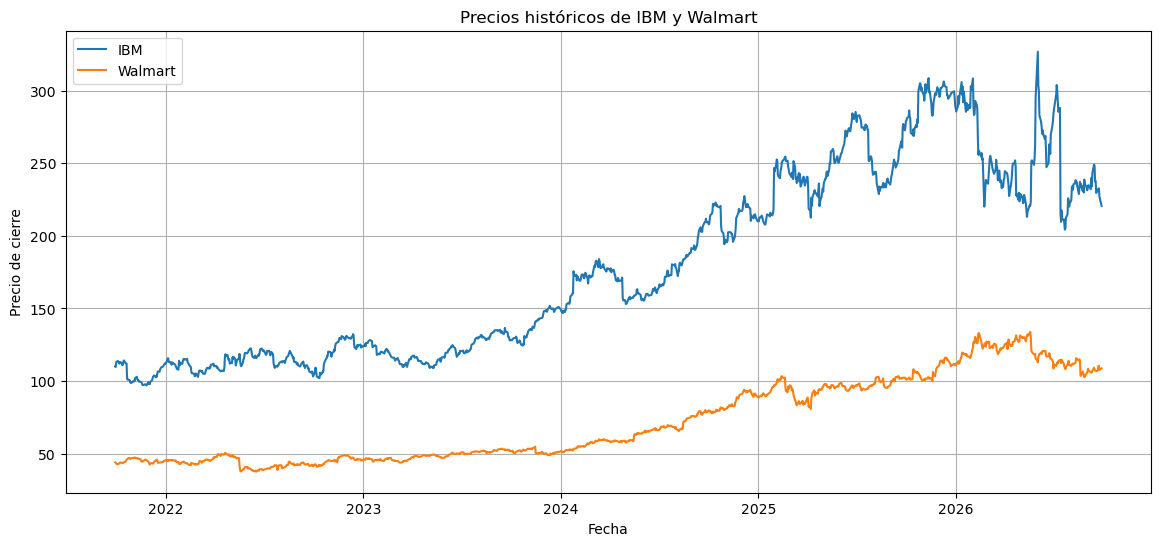

In [8]:
# ============================================
# 2. GRÁFICA COMPARATIVA DE PRECIOS
# ============================================

plt.figure(figsize=(14,6))

plt.plot(precios.index, precios['IBM'], label='IBM')
plt.plot(precios.index, precios['Walmart'], label='Walmart')

plt.title('Precios históricos de IBM y Walmart')
plt.xlabel('Fecha')
plt.ylabel('Precio de cierre')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# ============================================
# 3. CORRELACIÓN ENTRE IBM Y WALMART
# ============================================

correlacion = precios['IBM'].corr(precios['Walmart'])

print("Índice de correlación de Pearson:", correlacion)

Índice de correlación de Pearson: 0.9284107177262093


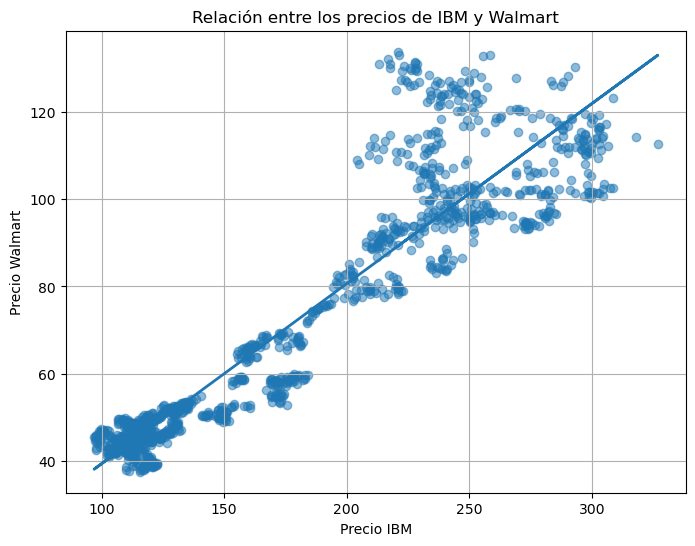

In [12]:
# ============================================
# 4. GRÁFICA DE DISPERSIÓN
# ============================================

plt.figure(figsize=(8,6))

plt.scatter(precios['IBM'], precios['Walmart'], alpha=0.5)

# Línea de tendencia
coef = np.polyfit(precios['IBM'], precios['Walmart'], 1)
linea = np.poly1d(coef)

plt.plot(
    precios['IBM'],
    linea(precios['IBM']),
    linewidth=2
)

plt.title('Relación entre los precios de IBM y Walmart')
plt.xlabel('Precio IBM')
plt.ylabel('Precio Walmart')
plt.grid(True)
plt.show()

In [14]:
if correlacion > 0:
    tipo = "positiva"
elif correlacion < 0:
    tipo = "negativa"
else:
    tipo = "nula"

print(f"La correlación entre IBM y Walmart es {tipo}.")
print(f"El valor de Pearson es {correlacion:.4f}.")

La correlación entre IBM y Walmart es positiva.
El valor de Pearson es 0.9284.


In [16]:
# Rendimientos diarios
rendimientos = precios.pct_change().dropna()

correlacion_rendimientos = rendimientos['IBM'].corr(
    rendimientos['Walmart']
)

print("Correlación de los rendimientos diarios:",
      round(correlacion_rendimientos, 4))

Correlación de los rendimientos diarios: 0.1063


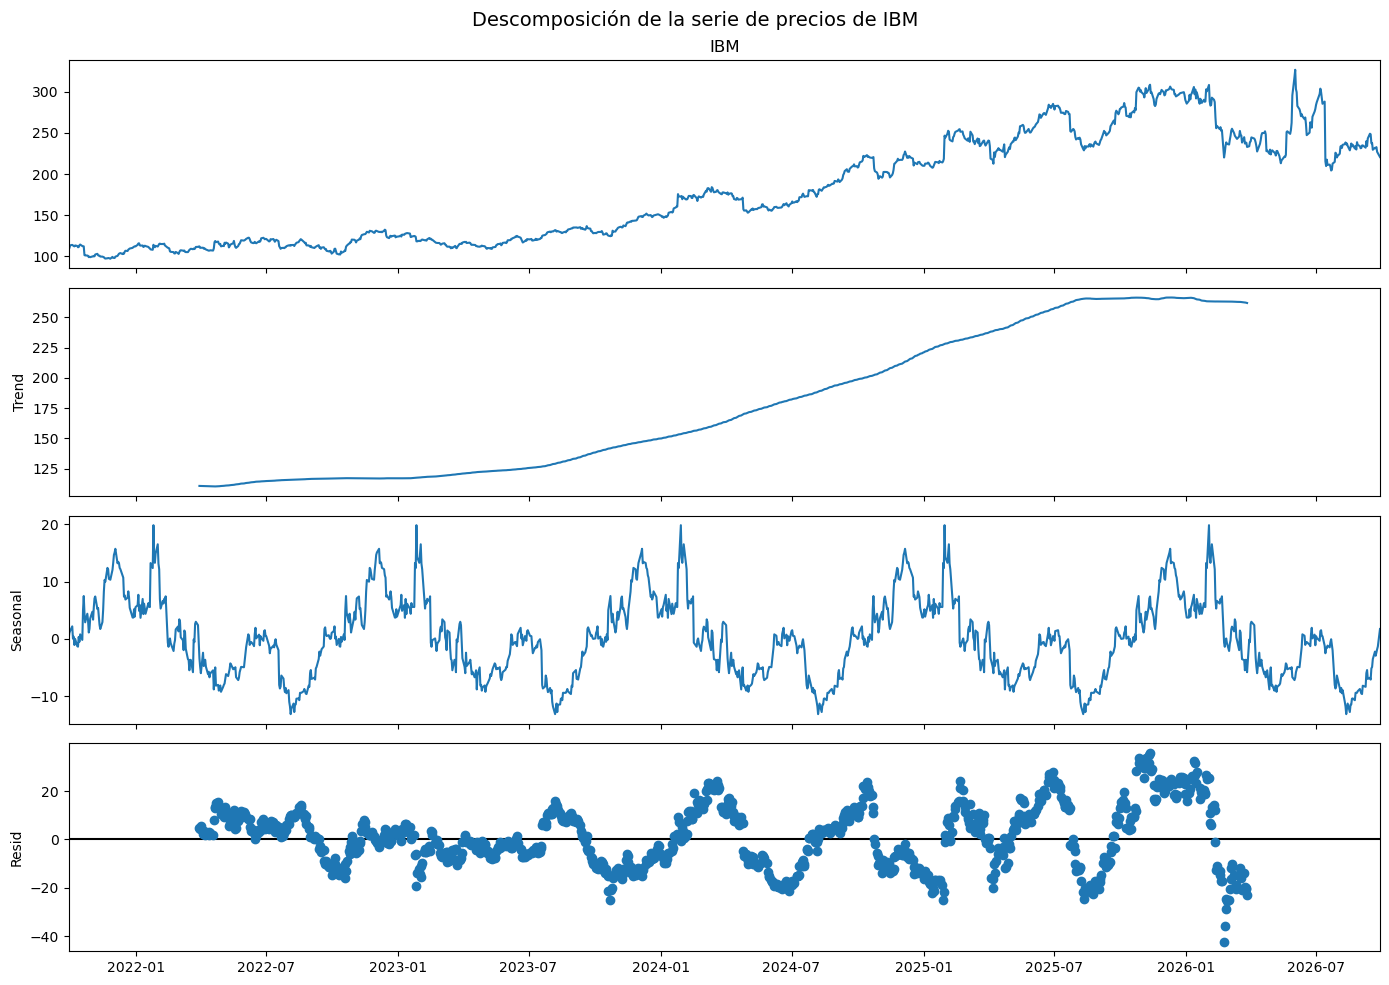

In [18]:
# ============================================
# 5. DESCOMPOSICIÓN DE IBM
# ============================================

from statsmodels.tsa.seasonal import seasonal_decompose

descomposicion_ibm = seasonal_decompose(
    ibm_close,
    model='additive',
    period=252
)

fig = descomposicion_ibm.plot()
fig.set_size_inches(14,10)

plt.suptitle('Descomposición de la serie de precios de IBM',
             fontsize=14)

plt.tight_layout()
plt.show()

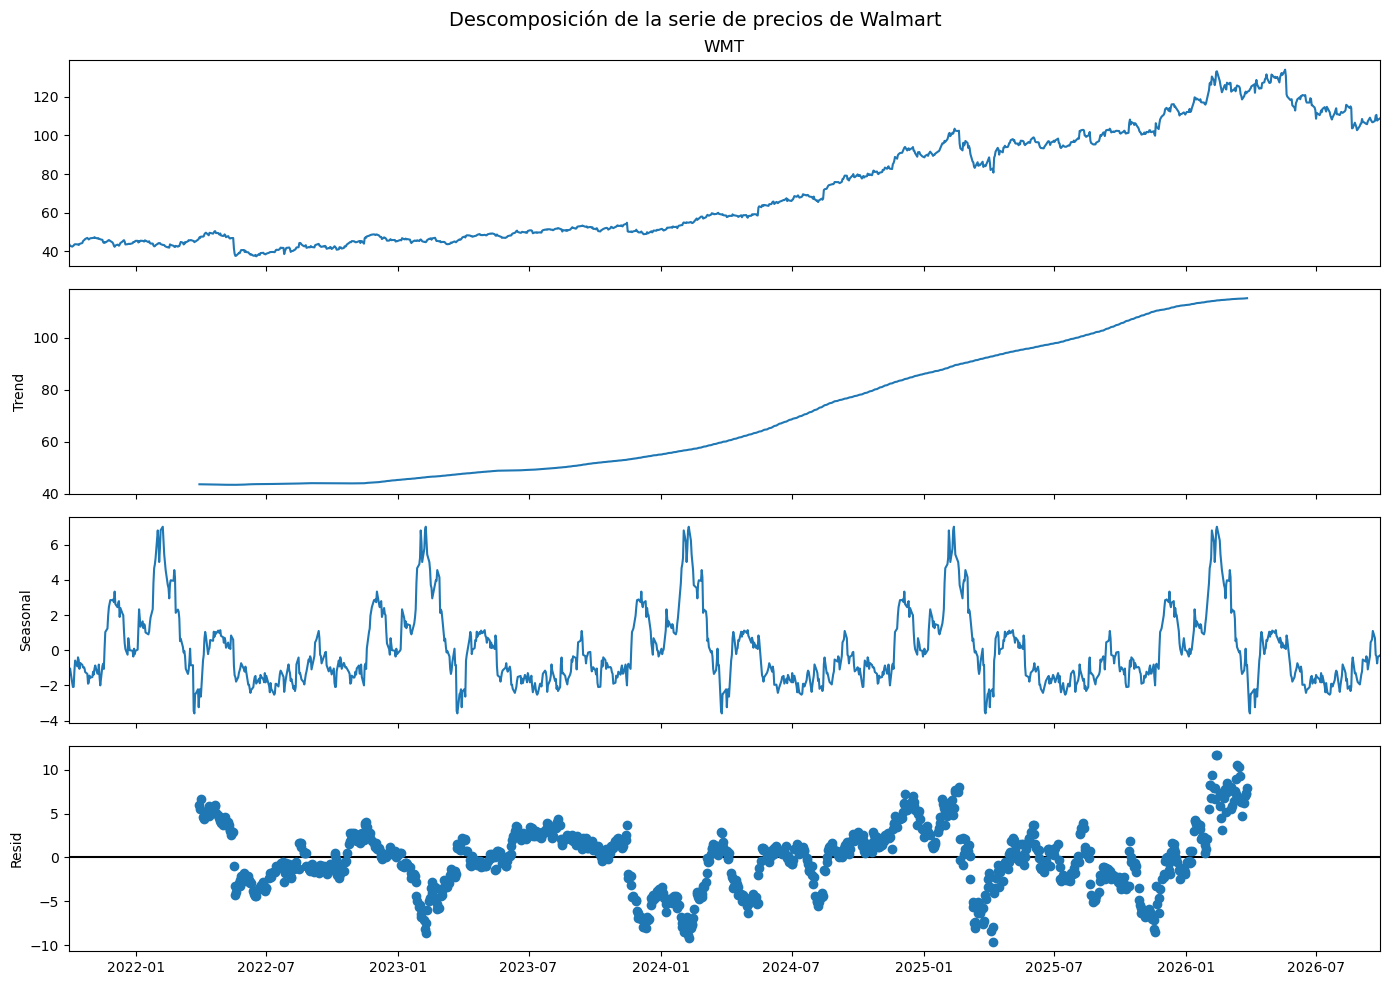

In [20]:
# ============================================
# 6. DESCOMPOSICIÓN DE WALMART
# ============================================

descomposicion_walmart = seasonal_decompose(
    walmart_close,
    model='additive',
    period=252
)

fig = descomposicion_walmart.plot()
fig.set_size_inches(14,10)

plt.suptitle('Descomposición de la serie de precios de Walmart',
             fontsize=14)

plt.tight_layout()
plt.show()

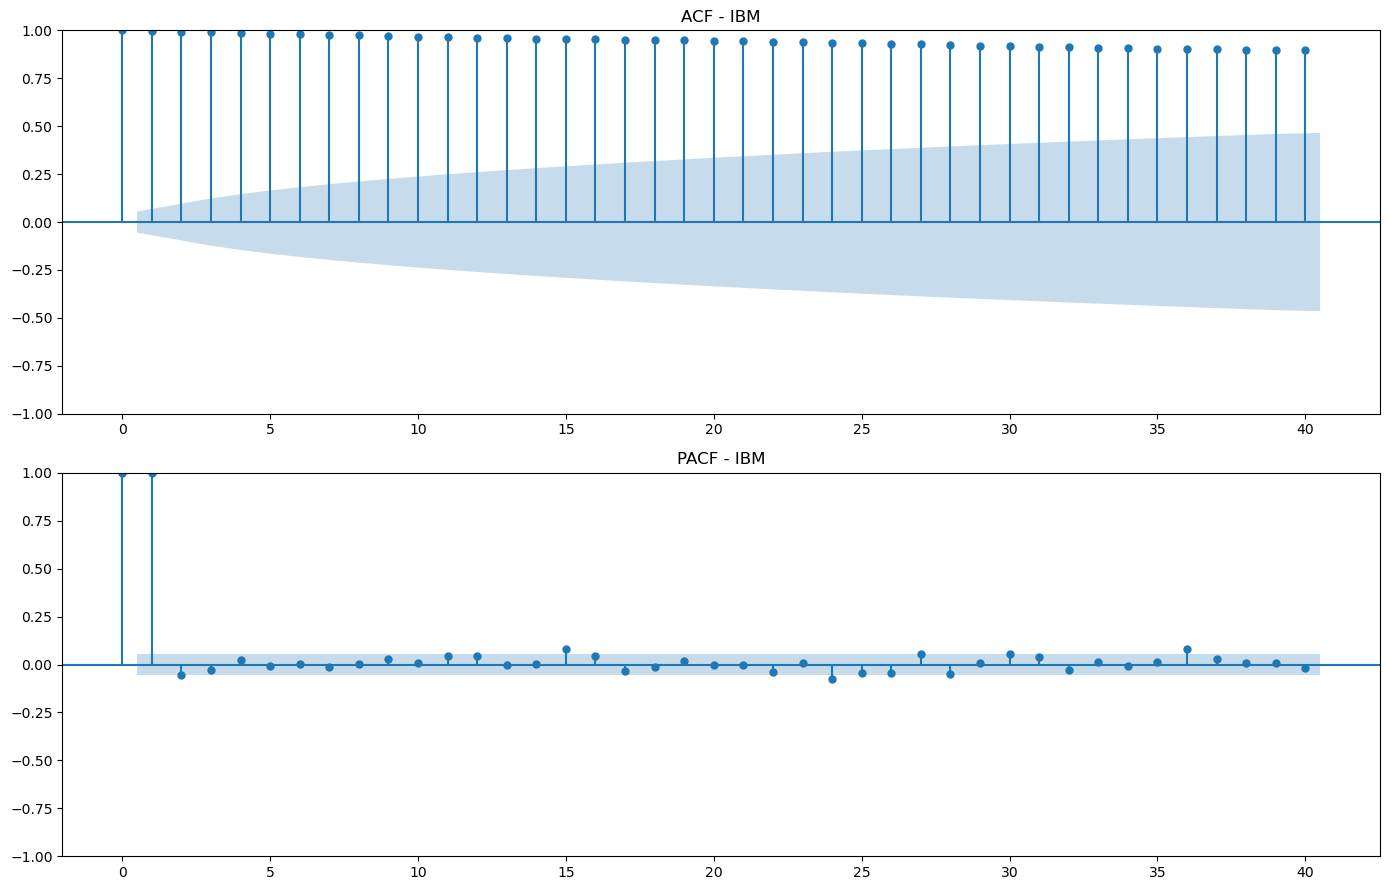

In [22]:
# ============================================
# 7. ACF Y PACF DE IBM
# ============================================

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14,9))

plot_acf(
    ibm_close.dropna(),
    lags=40,
    ax=axes[0]
)

axes[0].set_title('ACF - IBM')

plot_pacf(
    ibm_close.dropna(),
    lags=40,
    ax=axes[1],
    method='ywm'
)

axes[1].set_title('PACF - IBM')

plt.tight_layout()
plt.show()

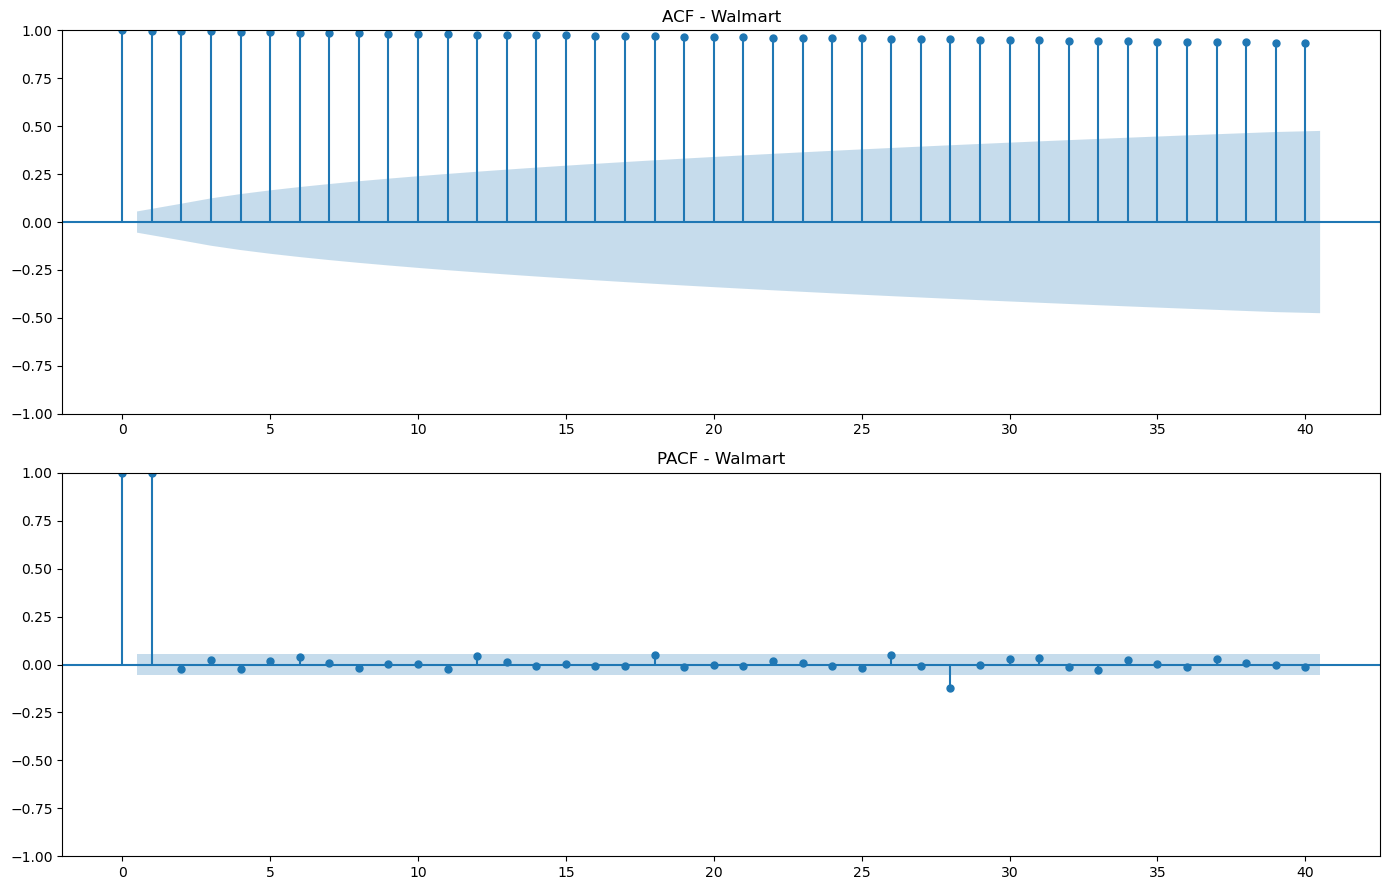

In [24]:
# ============================================
# 8. ACF Y PACF DE WALMART
# ============================================

fig, axes = plt.subplots(2, 1, figsize=(14,9))

plot_acf(
    walmart_close.dropna(),
    lags=40,
    ax=axes[0]
)

axes[0].set_title('ACF - Walmart')

plot_pacf(
    walmart_close.dropna(),
    lags=40,
    ax=axes[1],
    method='ywm'
)

axes[1].set_title('PACF - Walmart')

plt.tight_layout()
plt.show()

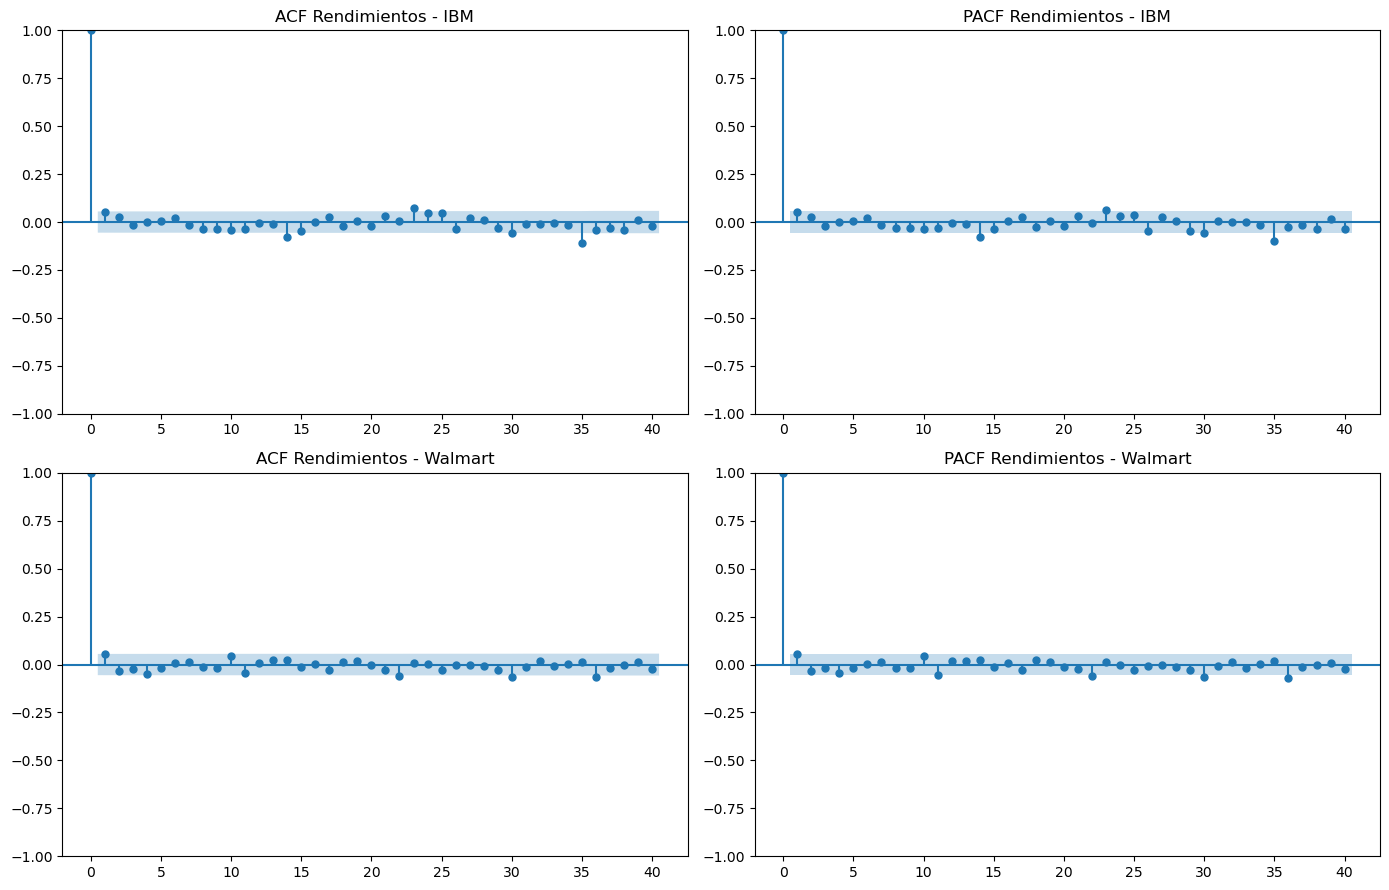

In [26]:
# ============================================
# 9. CORRELOGRAMAS DE LOS RENDIMIENTOS
# ============================================

fig, axes = plt.subplots(2, 2, figsize=(14,9))

plot_acf(
    rendimientos['IBM'],
    lags=40,
    ax=axes[0,0]
)
axes[0,0].set_title('ACF Rendimientos - IBM')

plot_pacf(
    rendimientos['IBM'],
    lags=40,
    ax=axes[0,1],
    method='ywm'
)
axes[0,1].set_title('PACF Rendimientos - IBM')

plot_acf(
    rendimientos['Walmart'],
    lags=40,
    ax=axes[1,0]
)
axes[1,0].set_title('ACF Rendimientos - Walmart')

plot_pacf(
    rendimientos['Walmart'],
    lags=40,
    ax=axes[1,1],
    method='ywm'
)
axes[1,1].set_title('PACF Rendimientos - Walmart')

plt.tight_layout()
plt.show()

In [28]:
# ============================================
# 10. PRUEBA DICKEY-FULLER
# ============================================

from statsmodels.tsa.stattools import adfuller

def prueba_adf(serie, nombre):
    
    resultado = adfuller(serie.dropna())
    
    estadistico = resultado[0]
    p_value = resultado[1]
    
    print("\n" + "="*50)
    print(nombre)
    print("="*50)
    
    print("Estadístico ADF:", round(estadistico, 4))
    print("p-value:", round(p_value, 6))
    
    print("\nValores críticos:")
    
    for nivel, valor in resultado[4].items():
        print(f"{nivel}: {valor:.4f}")
    
    if p_value < 0.05:
        print("\nConclusión: La serie es ESTACIONARIA.")
    else:
        print("\nConclusión: La serie NO es estacionaria.")


prueba_adf(ibm_close, "IBM")
prueba_adf(walmart_close, "Walmart")


IBM
Estadístico ADF: -1.0765
p-value: 0.724342

Valores críticos:
1%: -3.4356
5%: -2.8639
10%: -2.5680

Conclusión: La serie NO es estacionaria.

Walmart
Estadístico ADF: -0.5028
p-value: 0.891475

Valores críticos:
1%: -3.4356
5%: -2.8639
10%: -2.5680

Conclusión: La serie NO es estacionaria.


In [30]:
# ============================================
# 11. DICKEY-FULLER DE PRIMERAS DIFERENCIAS
# ============================================

ibm_diff = ibm_close.diff().dropna()
walmart_diff = walmart_close.diff().dropna()

prueba_adf(ibm_diff, "IBM - Primera diferencia")
prueba_adf(walmart_diff, "Walmart - Primera diferencia")


IBM - Primera diferencia
Estadístico ADF: -11.6695
p-value: 0.0

Valores críticos:
1%: -3.4356
5%: -2.8639
10%: -2.5680

Conclusión: La serie es ESTACIONARIA.

Walmart - Primera diferencia
Estadístico ADF: -25.789
p-value: 0.0

Valores críticos:
1%: -3.4356
5%: -2.8639
10%: -2.5680

Conclusión: La serie es ESTACIONARIA.


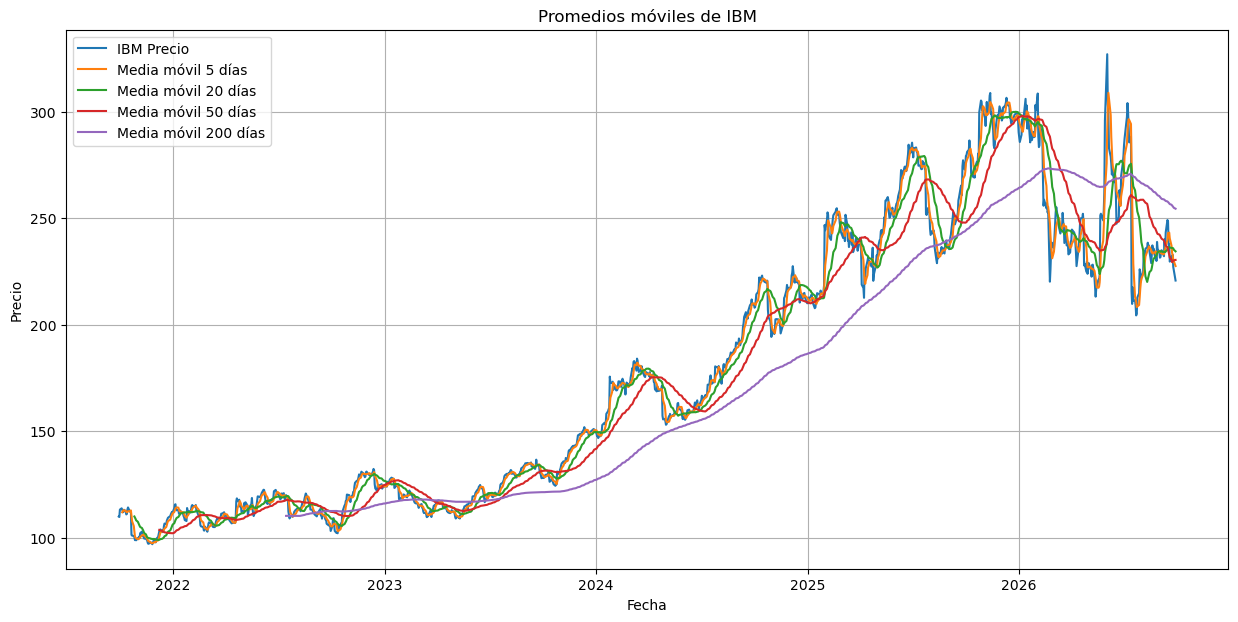

In [32]:
# ============================================
# 12. PROMEDIOS MÓVILES - IBM
# ============================================

plt.figure(figsize=(15,7))

plt.plot(
    ibm_close,
    label='IBM Precio'
)

plt.plot(
    ibm_close.rolling(5).mean(),
    label='Media móvil 5 días'
)

plt.plot(
    ibm_close.rolling(20).mean(),
    label='Media móvil 20 días'
)

plt.plot(
    ibm_close.rolling(50).mean(),
    label='Media móvil 50 días'
)

plt.plot(
    ibm_close.rolling(200).mean(),
    label='Media móvil 200 días'
)

plt.title('Promedios móviles de IBM')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

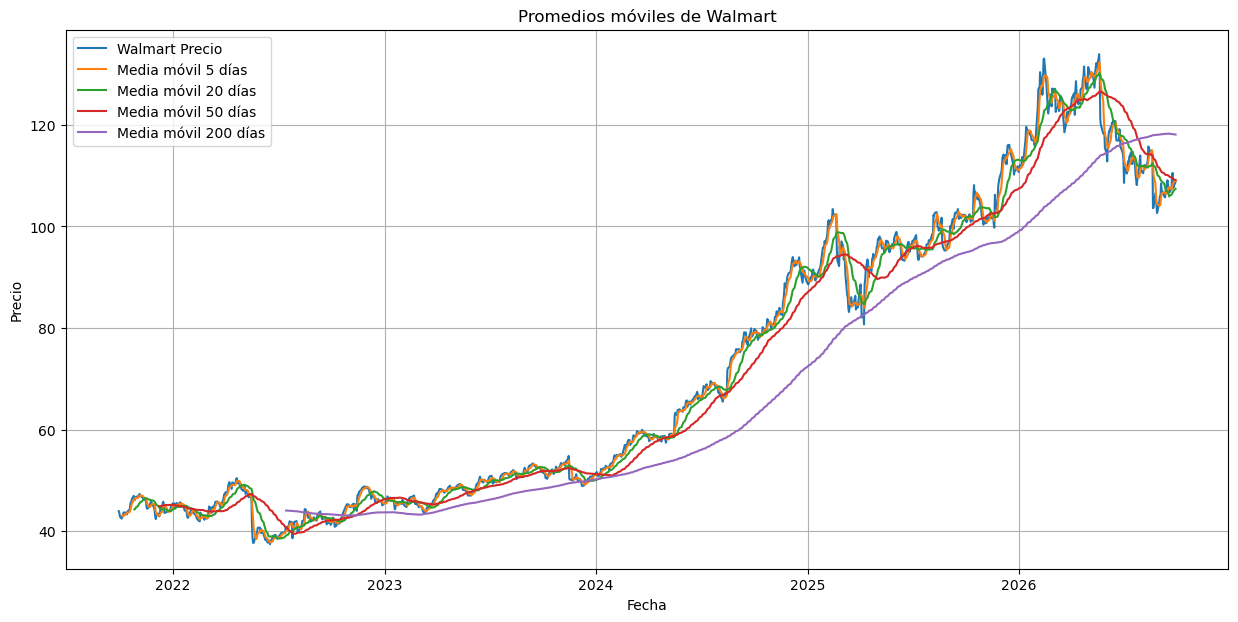

In [34]:
# ============================================
# 13. PROMEDIOS MÓVILES - WALMART
# ============================================

plt.figure(figsize=(15,7))

plt.plot(
    walmart_close,
    label='Walmart Precio'
)

plt.plot(
    walmart_close.rolling(5).mean(),
    label='Media móvil 5 días'
)

plt.plot(
    walmart_close.rolling(20).mean(),
    label='Media móvil 20 días'
)

plt.plot(
    walmart_close.rolling(50).mean(),
    label='Media móvil 50 días'
)

plt.plot(
    walmart_close.rolling(200).mean(),
    label='Media móvil 200 días'
)

plt.title('Promedios móviles de Walmart')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()


In [36]:
# ============================================
# 14. PRONÓSTICO DEL SIGUIENTE DÍA - IBM
# ============================================

ventana = 5

pronostico_ibm = ibm_close.tail(ventana).mean()

ultimo_precio_ibm = ibm_close.iloc[-1]

print("Último precio de IBM:", round(float(ultimo_precio_ibm), 2))
print("Pronóstico para el siguiente día:",
      round(float(pronostico_ibm), 2))

Último precio de IBM: 220.67
Pronóstico para el siguiente día: 227.48


In [38]:
# ============================================
# 15. PRONÓSTICO DEL SIGUIENTE DÍA - WALMART
# ============================================

pronostico_walmart = walmart_close.tail(ventana).mean()

ultimo_precio_walmart = walmart_close.iloc[-1]

print("Último precio de Walmart:",
      round(float(ultimo_precio_walmart), 2))

print("Pronóstico para el siguiente día:",
      round(float(pronostico_walmart), 2))

Último precio de Walmart: 108.73
Pronóstico para el siguiente día: 108.99


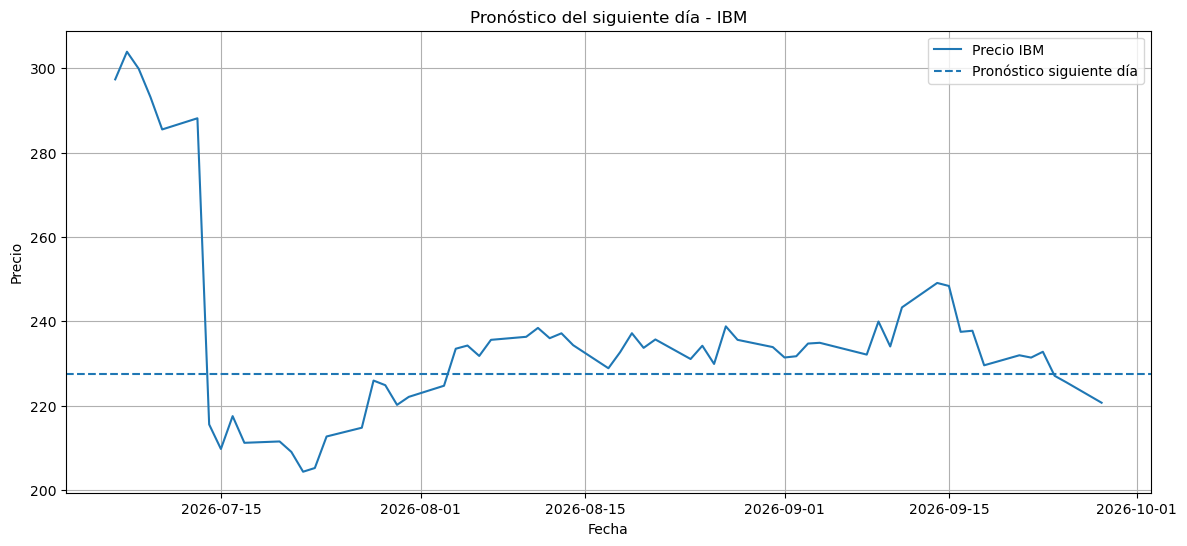

In [40]:
# ============================================
# 16. GRÁFICA DEL PRONÓSTICO IBM
# ============================================

ultimos_ibm = ibm_close.tail(60)

plt.figure(figsize=(14,6))

plt.plot(
    ultimos_ibm.index,
    ultimos_ibm.values,
    label='Precio IBM'
)

plt.axhline(
    float(pronostico_ibm),
    linestyle='--',
    label='Pronóstico siguiente día'
)

plt.title('Pronóstico del siguiente día - IBM')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

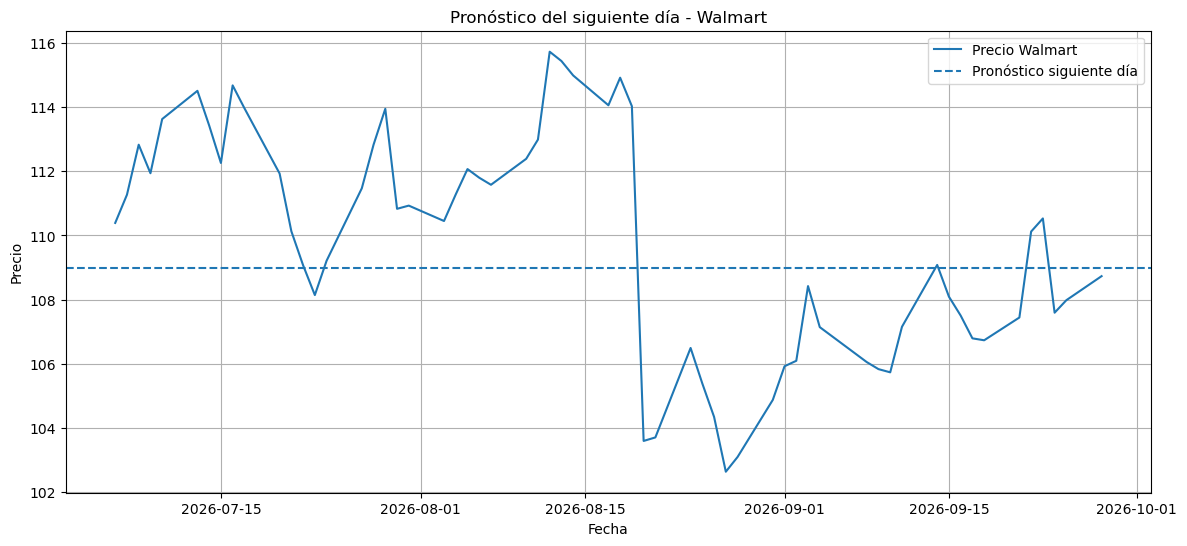

In [42]:
# ============================================
# 17. GRÁFICA DEL PRONÓSTICO WALMART
# ============================================

ultimos_walmart = walmart_close.tail(60)

plt.figure(figsize=(14,6))

plt.plot(
    ultimos_walmart.index,
    ultimos_walmart.values,
    label='Precio Walmart'
)

plt.axhline(
    float(pronostico_walmart),
    linestyle='--',
    label='Pronóstico siguiente día'
)

plt.title('Pronóstico del siguiente día - Walmart')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

In [44]:
# ============================================
# 18. BACKTESTING DEL PROMEDIO MÓVIL
# ============================================

def evaluar_media_movil(serie, ventana=5):
    
    datos = serie.dropna().copy()
    
    pronosticos = datos.rolling(ventana).mean().shift(1)
    
    comparacion = pd.DataFrame({
        'Real': datos,
        'Pronóstico': pronosticos
    }).dropna()
    
    mae = mean_absolute_error(
        comparacion['Real'],
        comparacion['Pronóstico']
    )
    
    rmse = np.sqrt(
        mean_squared_error(
            comparacion['Real'],
            comparacion['Pronóstico']
        )
    )
    
    return comparacion, mae, rmse


eval_ibm, mae_ibm, rmse_ibm = evaluar_media_movil(
    ibm_close,
    ventana=5
)

eval_walmart, mae_walmart, rmse_walmart = evaluar_media_movil(
    walmart_close,
    ventana=5
)

print("IBM")
print("MAE:", round(mae_ibm, 4))
print("RMSE:", round(rmse_ibm, 4))

print("\nWalmart")
print("MAE:", round(mae_walmart, 4))
print("RMSE:", round(rmse_walmart, 4))

IBM
MAE: 3.8787
RMSE: 6.9058

Walmart
MAE: 1.1471
RMSE: 1.7591


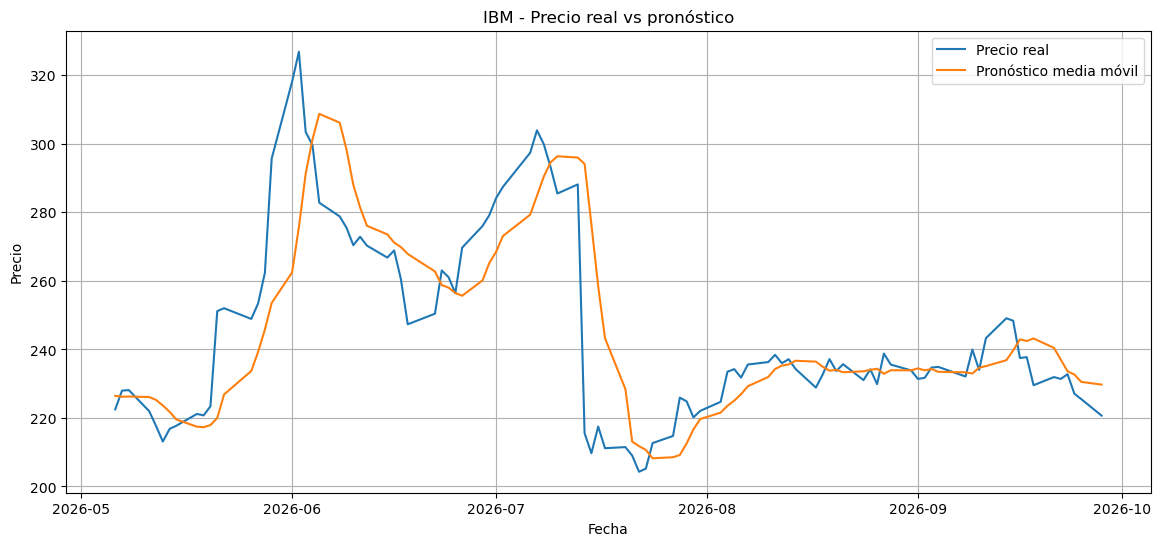

In [46]:
# ============================================
# 19. EVALUACIÓN GRÁFICA IBM
# ============================================

plt.figure(figsize=(14,6))

plt.plot(
    eval_ibm['Real'].tail(100),
    label='Precio real'
)

plt.plot(
    eval_ibm['Pronóstico'].tail(100),
    label='Pronóstico media móvil'
)

plt.title('IBM - Precio real vs pronóstico')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

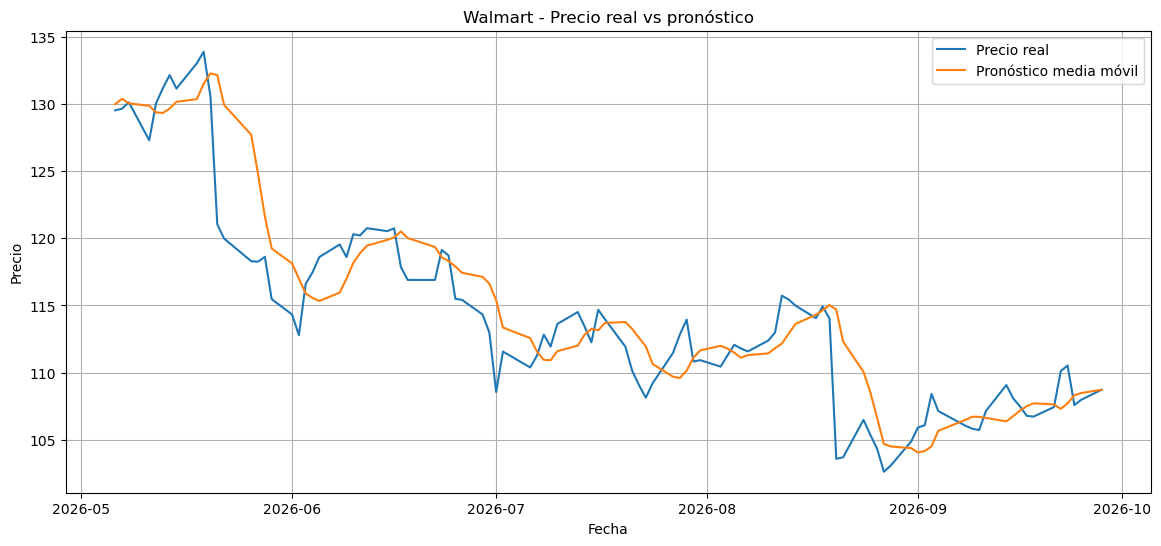

In [48]:
# ============================================
# 20. EVALUACIÓN GRÁFICA WALMART
# ============================================

plt.figure(figsize=(14,6))

plt.plot(
    eval_walmart['Real'].tail(100),
    label='Precio real'
)

plt.plot(
    eval_walmart['Pronóstico'].tail(100),
    label='Pronóstico media móvil'
)

plt.title('Walmart - Precio real vs pronóstico')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()